In [1]:
import numpy as np
import torch
import transformers
import datasets

## **Vision Transformer**
This ipynb aims to go from the most basic ready to use implementation of transformers for Vision to a completely self made, trial-and-error, implementation of the architectures. We first start out by using the ready made implementation from huggingface.

- Vision transformers (2021) propose and encoder only architecture with patches as tokens for classification tasks. Great performance gains were obserevd when the model was pretrained on a large corpus and then finetuned on smaller datasets. ([An image is worth 16x16 words](https://arxiv.org/pdf/2010.11929)).
- For generation Diffusion Transformers (DiT) are the current state of the art. Before them, autoregressive methods of generating images were devised:
    - (2018) [Image Transformer](https://arxiv.org/abs/1802.05751): Performed local attention at a pixel level, this was before patch as a token interpretation was proposed in the 2021 ViT paper.
    - (2020) [VQGAN](https://arxiv.org/abs/2012.09841): First papers to use patches as tokens for generation, still not pure transformer architecture. 

In [ ]:
# !mkdir -p datasets/mnist/

In [3]:
# Get dataset, lets start with MNIST
dataset = datasets.load_dataset("ylecun/mnist", cache_dir="./datasets/mnist")

# Train test split is inherent in huggingface dataset for MNIST
dataset

README.md:   0%|          | 0.00/6.97k [00:00<?, ?B/s]

mnist/train-00000-of-00001.parquet:   0%|          | 0.00/15.6M [00:00<?, ?B/s]

mnist/test-00000-of-00001.parquet:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

In [4]:
# Add transform to dataset to convert images to tensors and normalize them
def transform_fn(batch):
    inputs = processor([img.convert("RGB") for img in batch["image"]], return_tensors="pt")
    inputs["labels"] = batch["label"]
    return inputs

dataset["train"] = dataset["train"].with_transform(transform_fn)
dataset["test"] = dataset["test"].with_transform(transform_fn)

In [5]:
# Initialize the model and tokenizer
model_name = "google/vit-base-patch16-224-in21k"
model = transformers.ViTForImageClassification.from_pretrained(model_name, num_labels=10)
model

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/6 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
encoder.layer.{0...11}.attention.attention.value.weight | UNEXPECTED | 
encoder.layer.{0...11}.intermediate.dense.weight        | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_before.weight          | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.key.weight   | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.query.bias   | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.bias      | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.weight              | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_before.bias            | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_after.weight           | UNEXPECTED | 
encoder.layer.{0...11}.intermediate.dense.bias          | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.bias   

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out

In [6]:
processor = transformers.AutoImageProcessor.from_pretrained(model_name)
pipeline = transformers.ImageClassificationPipeline(model=model, feature_extractor=processor, device=0 if torch.cuda.is_available() else -1)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [7]:
# Train on the dataset
model.to("cuda" if torch.cuda.is_available() else "cpu")
model.train()
data_collator = transformers.DefaultDataCollator()
train_args = transformers.TrainingArguments(output_dir="./results", save_strategy="epoch", learning_rate=2e-5, per_device_train_batch_size=32, per_device_eval_batch_size=32, num_train_epochs=3, weight_decay=0.01, logging_dir="./logs", logging_steps=10, remove_unused_columns=False, load_best_model_at_end=True, eval_strategy="epoch")
trainer = transformers.Trainer(model, train_dataset=dataset["train"], eval_dataset=dataset["test"], args=train_args, data_collator=data_collator, processing_class = processor)
trainer.train()


[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Epoch,Training Loss,Validation Loss
1,0.169227,0.181956
2,0.097765,0.083635
3,0.032227,0.058834


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5625, training_loss=0.2571881902668211, metrics={'train_runtime': 748.7232, 'train_samples_per_second': 240.409, 'train_steps_per_second': 7.513, 'total_flos': 1.394955826274304e+19, 'train_loss': 0.2571881902668211, 'epoch': 3.0})

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Predicted label: LABEL_7, Score: 0.9851, GT label: 7


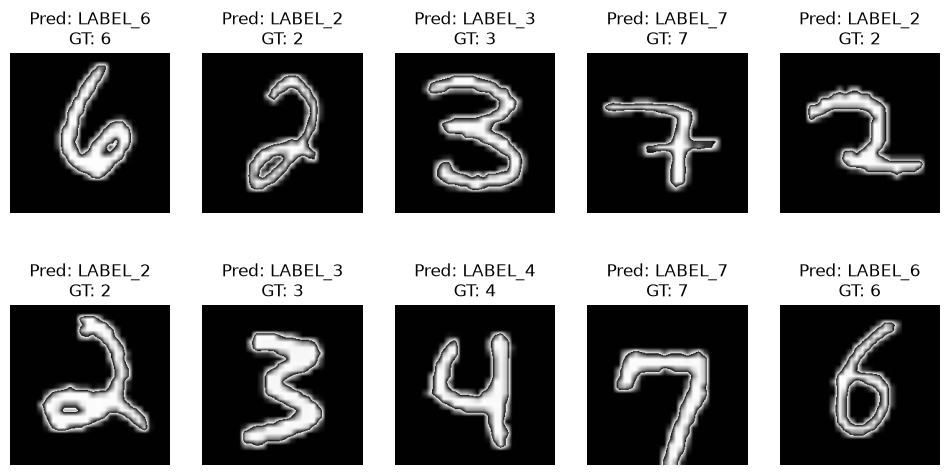

In [15]:
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt
# Run inference on an image

img = dataset["test"][0]['pixel_values']
prediction = pipeline(F.to_pil_image(img))
print(f"Predicted label: {prediction[0]['label']}, Score: {prediction[0]['score']:.4f}, GT label: {dataset['test'][0]['labels']}")
indices = np.random.choice(len(dataset["test"]), 10, replace=False)
plt.subplots(2, 5, figsize=(12, 6))
for i, idx in enumerate(indices):
    img = dataset["test"][idx]['pixel_values']
    prediction = pipeline(F.to_pil_image(img))
    plt.subplot(2, 5, i + 1)
    plt.imshow(F.to_pil_image(img))
    plt.title(f"Pred: {prediction[0]['label']}\nGT: {dataset['test'][idx]['labels']}")
    plt.axis('off')

In [25]:
import evaluate

label_2_id = {"LABEL_" + str(i): i for i in range(10)}
# Overall test acc

metric = evaluate.load("accuracy")
score = metric.compute(predictions=[label_2_id[pipeline(F.to_pil_image(dataset["test"][i]['pixel_values']))[0]['label']] for i in range(len(dataset["test"]))], references=[dataset["test"][i]['labels'] for i in range(len(dataset["test"]))])
print(f"Overall test accuracy: {score['accuracy']:.4f}")

Overall test accuracy: 0.8359
